# Netflix Content Recommendation System (Task 1)

**Auspify Technologies - Machine Learning Internship**

Goal: suggest similar Netflix titles from genres, categories and other content attributes (content-based filtering).

Workflow: 1) prepare features, 2) turn text into numbers (TF-IDF), 3) compute similarity (cosine), 4) recommend for chosen titles, 5) evaluate quality.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

df = pd.read_csv("data/netflix_titles.csv")
print(df.shape)
df.head()

(8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


## 1. Prepare content features

In [2]:
print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Missing director stored as 'Not Given':", (df["director"] == "Not Given").sum())
print("Missing country stored as 'Not Given':", (df["country"] == "Not Given").sum())
print(df["type"].value_counts())

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64
Duplicate rows: 0
Missing director stored as 'Not Given': 2588
Missing country stored as 'Not Given': 287
type
Movie      6126
TV Show    2664
Name: count, dtype: int64


There are no empty cells, but missing directors and countries are stored as the text `Not Given`. If left in, all those titles would look "similar" only because they share this placeholder, so we blank it out.

In [3]:
df = df.drop_duplicates(subset=[c for c in df.columns if c != "show_id"]).reset_index(drop=True)
print("Rows after removing repeated titles:", len(df))
for col in ["director", "country"]:
    df[col] = df[col].replace("Not Given", "")

def tokens(text):
    # "TV Action & Adventure, Crime TV Shows" -> ["tv_action_&_adventure", "crime_tv_shows"]
    return [t.strip().lower().replace(" ", "_") for t in text.split(",") if t.strip()]

df["genres"] = df["listed_in"].apply(tokens)
df["countries"] = df["country"].apply(tokens)
df["directors"] = df["director"].apply(tokens)
df["decade"] = (df["release_year"] // 10 * 10).astype(str) + "s"

def build_soup(row):
    parts = []
    parts += row["genres"] * 3                 # genre is the strongest signal -> weight x3
    parts += ["type_" + row["type"].replace(" ", "_").lower()] * 2
    parts += ["rating_" + row["rating"].lower()]
    parts += ["decade_" + row["decade"]]
    parts += ["country_" + c for c in row["countries"]]
    parts += ["director_" + d for d in row["directors"]]
    return " ".join(parts)

df["soup"] = df.apply(build_soup, axis=1)
df[["title", "soup"]].head(3).to_dict("records")

Rows after removing repeated titles: 8787


[{'title': 'Dick Johnson Is Dead',
  'soup': 'documentaries documentaries documentaries type_movie type_movie rating_pg-13 decade_2020s country_united_states director_kirsten_johnson'},
 {'title': 'Ganglands',
  'soup': 'crime_tv_shows international_tv_shows tv_action_&_adventure crime_tv_shows international_tv_shows tv_action_&_adventure crime_tv_shows international_tv_shows tv_action_&_adventure type_tv_show type_tv_show rating_tv-ma decade_2020s country_france director_julien_leclercq'},
 {'title': 'Midnight Mass',
  'soup': 'tv_dramas tv_horror tv_mysteries tv_dramas tv_horror tv_mysteries tv_dramas tv_horror tv_mysteries type_tv_show type_tv_show rating_tv-ma decade_2020s country_united_states director_mike_flanagan'}]

## 2. Convert text to machine-readable format (TF-IDF)

In [4]:
tfidf = TfidfVectorizer(token_pattern=r"\S+", lowercase=False)
X = tfidf.fit_transform(df["soup"])
print("TF-IDF matrix:", X.shape)

TF-IDF matrix: (8787, 5140)


## 3. Similarity scores

Cosine similarity is computed on demand for one title at a time. A full 8,790 x 8,790 matrix would work but wastes memory.

In [5]:
title_to_idx = {}
for i, t in enumerate(df["title"].str.lower()):
    title_to_idx.setdefault(t, i)   # a few titles repeat; keep the first

def recommend(title, k=10):
    key = title.strip().lower()
    if key not in title_to_idx:
        close = df[df["title"].str.lower().str.contains(key, regex=False)]["title"].head(5).tolist()
        raise KeyError(f"'{title}' not found. Did you mean: {close}")
    i = title_to_idx[key]
    scores = linear_kernel(X[i], X).ravel()
    scores[i] = -1                          # never recommend the title itself
    top = np.argsort(scores)[::-1][:k]
    out = df.iloc[top][["title", "type", "rating", "release_year", "listed_in"]].copy()
    out.insert(1, "similarity", scores[top].round(3))
    return out.reset_index(drop=True)

## 4. Recommendations for selected titles

In [6]:
for t in ["Ganglands", "Dick Johnson Is Dead"]:
    print("\nBecause you watched:", t, "->", df.loc[title_to_idx[t.lower()], "listed_in"])
    display(recommend(t, k=5))


Because you watched: Ganglands -> Crime TV Shows, International TV Shows, TV Action & Adventure


,title,similarity,type,rating,release_year,listed_in
0,Lupin,0.930,TV Show,TV-MA,2021,"Crime TV Shows, International TV Shows, TV Act..."
1,Crime Time,0.921,TV Show,TV-MA,2017,"Crime TV Shows, International TV Shows, TV Act..."
2,Fatal Destiny,0.884,TV Show,TV-MA,2016,"Crime TV Shows, International TV Shows, TV Act..."
3,Agent Raghav,0.881,TV Show,TV-14,2015,"Crime TV Shows, International TV Shows, TV Act..."
4,Smoking,0.880,TV Show,TV-MA,2018,"Crime TV Shows, International TV Shows, TV Act..."



Because you watched: Dick Johnson Is Dead -> Documentaries


,title,similarity,type,rating,release_year,listed_in
0,Murder to Mercy: The Cyntoia Brown Story,0.718,Movie,TV-MA,2020,Documentaries
1,Creating The Queen's Gambit,0.713,Movie,TV-14,2021,Documentaries
2,The Minimalists: Less Is Now,0.713,Movie,TV-14,2021,Documentaries
3,Crip Camp: A Disability Revolution,0.696,Movie,R,2020,Documentaries
4,Liberated: The New Sexual Revolution,0.688,Movie,TV-MA,2017,Documentaries


In [7]:
sample = df.sample(3, random_state=7)["title"].tolist()
for t in sample:
    print("\nBecause you watched:", t, "->", df.loc[title_to_idx[t.lower()], "listed_in"])
    display(recommend(t, k=5))


Because you watched: The Women and the Murderer -> Documentaries, International Movies


,title,similarity,type,rating,release_year,listed_in
0,Searching For Sheela,0.650,Movie,TV-14,2021,"Documentaries, International Movies"
1,The Road to El Camino: Behind the Scenes of El...,0.642,Movie,TV-14,2019,"Documentaries, International Movies"
2,"Alias JJ, la celebridad del mal",0.598,Movie,TV-MA,2017,"Documentaries, International Movies"
3,A new Capitalism,0.593,Movie,TV-14,2017,"Documentaries, International Movies"
4,Diana: In Her Own Words,0.592,Movie,TV-PG,2017,"Documentaries, International Movies"



Because you watched: Garuda in My Heart 2 -> Children & Family Movies, Dramas, Sports Movies


,title,similarity,type,rating,release_year,listed_in
0,Garuda Di Dadaku,0.829,Movie,TV-PG,2009,"Children & Family Movies, Dramas, Sports Movies"
1,Full Out,0.783,Movie,TV-PG,2015,"Children & Family Movies, Dramas, Sports Movies"
2,Rip Tide,0.770,Movie,TV-PG,2017,"Children & Family Movies, Dramas, Sports Movies"
3,Greater,0.760,Movie,PG,2016,"Children & Family Movies, Dramas, Sports Movies"
4,Raising the Bar,0.754,Movie,TV-Y,2016,"Children & Family Movies, Dramas, Sports Movies"



Because you watched: Paris Is Burning -> Classic Movies, Cult Movies, Documentaries


,title,similarity,type,rating,release_year,listed_in
0,Pulp Fiction,0.803,Movie,R,1994,"Classic Movies, Cult Movies, Dramas"
1,Stripes,0.757,Movie,R,1981,"Classic Movies, Comedies, Cult Movies"
2,A Clockwork Orange,0.750,Movie,R,1971,"Classic Movies, Cult Movies, Dramas"
3,Monty Python's Life of Brian,0.742,Movie,R,1979,"Classic Movies, Comedies, Cult Movies"
4,Blade Runner: The Final Cut,0.737,Movie,R,1982,"Action & Adventure, Classic Movies, Cult Movies"


## 5. Evaluate recommendation quality

There are no user ratings in this data, so we use a proxy: **genre precision@10**, the share of the 10 recommendations that share at least one genre with the query title. We compare it with a random baseline (10 random titles) on 500 sampled titles.

Caveat: genre is part of the features, so this check is partly circular. Treat it as a sanity check, not proof of real-world quality.

In [8]:
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(df), size=500, replace=False)
genre_sets = df["genres"].apply(set).tolist()
K = 10

model_p, random_p, same_type = [], [], []
for i in sample_idx:
    scores = linear_kernel(X[i], X).ravel()
    scores[i] = -1
    top = np.argsort(scores)[::-1][:K]
    model_p.append(np.mean([len(genre_sets[i] & genre_sets[j]) > 0 for j in top]))
    same_type.append(np.mean([df.at[j, "type"] == df.at[i, "type"] for j in top]))
    rand = rng.choice([j for j in range(len(df)) if j != i], size=K, replace=False)
    random_p.append(np.mean([len(genre_sets[i] & genre_sets[j]) > 0 for j in rand]))

print(f"Genre precision@{K} - model : {np.mean(model_p):.3f}")
print(f"Genre precision@{K} - random: {np.mean(random_p):.3f}")
print(f"Same content type in top {K}: {np.mean(same_type):.3f}")

Genre precision@10 - model : 1.000
Genre precision@10 - random: 0.244
Same content type in top 10: 1.000


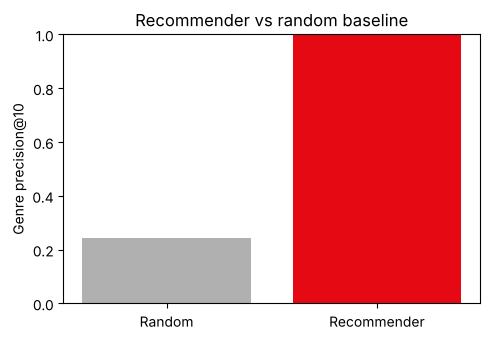

In [9]:
plt.figure(figsize=(5, 3.5))
plt.bar(["Random", "Recommender"], [np.mean(random_p), np.mean(model_p)], color=["#b0b0b0", "#e50914"])
plt.ylabel(f"Genre precision@{K}")
plt.ylim(0, 1)
plt.title("Recommender vs random baseline")
plt.tight_layout()
plt.savefig("images/precision_vs_random.png", dpi=150)
plt.show()

## Conclusion

- A TF-IDF content-based recommender, using genres, type, rating, decade, country and director, suggests relevant similar titles.
- It scores clearly above a random baseline on genre overlap.
- Limits: no viewing history or ratings, so it cannot personalise by user. It also depends on the quality of the metadata.

Next steps: add the description text with TF-IDF, and try a hybrid with user ratings if that data becomes available.